# Trabajo de Fin de Máster – Análisis de Big Data con Cassandra y PySpark

**Autor:** Josué Juan Hormiga Benítez  
**Fecha:** 15 de febrero de 2026

---
## Índice General

1. Clasificación de datos.
2. Consultas con Cassandra.
3. Análisis exploratorio con PySpark.
4. Análisis descriptivo con PySpark.
5. Análisis de correlación.
6. Selección de algoritmo predictivo.
7. Explicación de la toma del algoritmo.
8. Conclusión.


---

## I. Clasificación de datos

Vamos a clasificar los datos para entender los tipos que vamos a manejar y como deberemos tratarlos más adelante:
| Nombre del campo | Tipo de dato |
|---|---|
| CustomerID | Texto |
| Age | Flotante |
| Gender | Texto |
| Tenure | Flotante |
| Usage Frequency | Flotante |
| Support Calls | Flotante |
| Payment Delay | Flotante |
| Subscription Type | Texto |
| Contract Length | Texto |
| Total Spend | Flotante |
| Last Interaction | Flotante |
| Churn_YesNo | Texto |

Todos los datos son de tipo float excepto *CustomerID*, *Gender*, *Subscription_Type*, *Contract_Length*, y *Churn_YesNo* que son de tipo string. Más adelante, de ser necesario para incorporar las variables a nuestro modelo (salvo *CustomerID*, que se nos indica explícitamente que no puede ser usado en modelos de aprendizaje) podremos hacer una transformación a tipo flotante y añadirlas a nuestros modelos de aprendizaje.


---

## II. Consultas con Cassandra

Lo primero de todo para empezar esta tarea es tener nociones básicas para poder acceder a la interfaz, cargar los datos y empezar a hacer consultas. Vamos a ir paso a paso:

- Acceder al enlace: https://killercoda.com/playgrounds/scenario/ubuntu
- Nos aparecerá la siguiente ventana, donde pulsaremos start y tendremos 60 minutos para trabajar.
- Una vez que pulsamos start debemos ejecutar los siguientes comandos en el orden que vamos a indicar:

1. ***Descargamos la imagen de Cassandra***: `docker pull cassandra:3.11`
2. ***Creamos la red***: `docker network create cassandra`
3. ***Iniciamos el contenedor***: `docker run --rm -d --name cassandra --hostname cassandra --network cassandra cassandra:3.11`
4. ***Conectamos con cqlsh***: `docker run --rm -it --network cassandra nuvo/docker-cqlsh cqlsh cassandra 9042 --cqlversion='3.4.4'`

Ahora empezamos a trabajar con los datos y hacemos las consultas que se nos indica. El procedimiento que se ha seguido es el siguiente:

1. Creamos la base de datos llamada *customer_churn* donde cada dato se almacena en un único nodo del cluster.
2. Nos metemos en la base de datos.
3. Eliminamos cualquier posible tabla existente con el nombre que vamos a querer utilizar por si ha quedado algún registro de las pruebas anteriores.
4. Creamos una tabla con cada tipo previamente definido y la nombramos como *customers*.
5. Salimos de la base de datos.
6. Importamos los datos a Cassandra.
7. Nos metemos en la base de datos y copiamos los datos que hemos importado dentro de nuestra tabla que habíamos definido previamente con los campos y los tipos adecuadamente.
8. Creamos unos índices que nos permitan recorrer los datos en las consultas posteriores en las columnas *subscription_type* y *contract_length*.
9. Hacemos la consulta de conteo de clientes con el tipo de subscripción *Basic*.
10. Hacemos la consulta de conteo de clientes con el tipo de subscripción *Basic* y longitud de contrato *Annual*.
11. Salimos y guardamos el registro de comandos en un .txt para añadir al entregable.

Tras hacer todas las consultas llegamos a la conclusión de que tenemos **3233 suscripciones básicas**, y **1250 suscripciones básicas anuales**.


> **Nota:** El siguiente bloque contiene el script completo de Cassandra tal como fue ejecutado en la terminal. Este código **no se ejecuta en Colab** (requiere un entorno Docker con Cassandra). Se incluye aquí como registro del procedimiento seguido para obtener los resultados previamente expuestos


In [60]:
# ============================================================
# CÓDIGO CASSANDRA – Ejecutar en terminal con Docker
# (No ejecutar en Colab)
# ============================================================

# cat > /root/TAB1.txt << 'EOF'

# 1. Descargar imagen Cassandra
# docker pull cassandra:3.11

# 2. Crear red
# docker network create cassandra

# 3. Iniciar contenedor
# docker run --rm -d --name cassandra --hostname cassandra --network cassandra cassandra:3.11

# 4. Conectar con cqlsh y crear keyspace y tabla
# docker run --rm -it --network cassandra nuvo/docker-cqlsh cqlsh cassandra 9042 --cqlversion='3.4.4'

# CREATE KEYSPACE IF NOT EXISTS customer_churn WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1};
# USE customer_churn;
# DROP TABLE IF EXISTS customers;
# CREATE TABLE IF NOT EXISTS customers (
#     customer_id TEXT PRIMARY KEY,
#     age DOUBLE,
#     gender TEXT,
#     tenure DOUBLE,
#     usage_frequency DOUBLE,
#     support_calls DOUBLE,
#     payment_delay DOUBLE,
#     subscription_type TEXT,
#     contract_length TEXT,
#     total_spend DOUBLE,
#     last_interaction DOUBLE,
#     Churn_YesNo TEXT
# );
# EXIT

# 5. Copiar CSV al contenedor
# docker cp /root/customer_churn_10k.csv cassandra:/root/customer_churn_10k.csv

# 6. Importar CSV y crear índices
# docker exec -it cassandra cqlsh

# USE customer_churn;
# COPY customers (customer_id, age, gender, tenure, usage_frequency, support_calls, payment_delay, subscription_type, contract_length, total_spend, last_interaction, Churn_YesNo)
# FROM '/root/customer_churn_10k.csv'
# WITH HEADER = TRUE AND DELIMITER = ',';

# CREATE INDEX IF NOT EXISTS ON customers (subscription_type);
# CREATE INDEX IF NOT EXISTS ON customers (contract_length);

# a. Consulta: clientes con tarifa Basic
# SELECT * FROM customers WHERE subscription_type = 'Basic';
# SELECT COUNT(*) FROM customers WHERE subscription_type = 'Basic';

# b. Consulta: clientes Basic con contrato Annual
# SELECT * FROM customers WHERE subscription_type = 'Basic' AND contract_length = 'Annual' ALLOW FILTERING;
# SELECT COUNT(*) FROM customers WHERE subscription_type = 'Basic' AND contract_length = 'Annual' ALLOW FILTERING;

# EXIT
# EOF

# Verificar que se guarda correctamente.
# cat /root/TAB1.txt


---

## III. Análisis exploratorio con PySpark

Para empezar con el análisis exploratorio lo primero de todo es acceder a Google Colab, donde prepararemos el entorno para el análisis de los datos. Se nos indica que el tratamiento de datos se debe hacer en PySpark, esto es debido a que la gran cantidad de datos que tenemos no es fácilmente manejable por la librería usual de Python, que viene siendo Pandas.

Para cargar los datos en el entorno debemos subir el archivo .csv a Google Drive. Una vez subidos vamos a seguir los siguientes pasos:

1. Instalamos el módulo de Spark en Python.
2. Importamos la sesión de Spark.
3. Importamos Google Drive como unidad física.
4. Cargamos los datos customers_churn en un Data Frame de Spark.
5. Resolvemos todas las peticiones que se nos preguntan.


In [61]:
# Instalamos PySpark
!pip install pyspark

In [62]:
# Importamos la librería que nos permite trabajar con Spark
from pyspark.sql import SparkSession

# Creamos la sesión o la recuperamos en caso de ya tenerla creada
spark = SparkSession.builder.appName("TFM_JosueHB").getOrCreate()

In [63]:
# Damos acceso a google drive para acceder a los datos
from google.colab import drive
drive.mount("/drive")

Drive already mounted at /drive; to attempt to forcibly remount, call drive.mount("/drive", force_remount=True).


In [64]:
# Cargamos la ruta correspondiente
customer_churn = "/drive/MyDrive/TFM/customer_churn_10k.csv"

# Cargamos los datos como un DataFrame de PySpark
sdf_customer_churn = spark.read.option("header", True).csv(customer_churn, sep = ",", inferSchema = True)

In [65]:
# Mostramos la estructura de los datos
sdf_customer_churn.show()

+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+
|CustomerID| Age|Gender|Tenure|Usage Frequency|Support Calls|Payment Delay|Subscription Type|Contract Length|Total Spend|Last Interaction|Churn_YesNo|
+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+
|  314921.0|36.0|  Male|  10.0|           14.0|          1.0|         20.0|         Standard|         Annual|     736.02|            27.0|         No|
|  401716.0|40.0|  Male|  20.0|           23.0|          4.0|          6.0|         Standard|      Quarterly|      897.3|            29.0|         No|
|   99832.0|36.0|Female|  52.0|           23.0|          1.0|          0.0|         Standard|      Quarterly|      697.0|            29.0|        Yes|
|  168747.0|65.0|  Male|  55.0|            3.0|         10.0|         14.0|            Basic| 

In [66]:
# Vemos los tipos de datos que se han inferido automáticamente
sdf_customer_churn.printSchema()

root
 |-- CustomerID: double (nullable = true)
 |-- Age: double (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Tenure: double (nullable = true)
 |-- Usage Frequency: double (nullable = true)
 |-- Support Calls: double (nullable = true)
 |-- Payment Delay: double (nullable = true)
 |-- Subscription Type: string (nullable = true)
 |-- Contract Length: string (nullable = true)
 |-- Total Spend: double (nullable = true)
 |-- Last Interaction: double (nullable = true)
 |-- Churn_YesNo: string (nullable = true)



Como podemos ver CustomerID se nos ha cargado con tipo flotante, sin embargo en el enunciado se nos pide que se cargue como tipo texto, por tanto debemos convertir el tipo de dato a texto para seguir la norma establecida.

In [67]:
# Importamos la librería que nos permite modificar columnas de un DataFrame tipo Spark
from pyspark.sql.functions import col

# Casteamos la columna a tipo string tal y como se nos indica
sdf_customer_churn = sdf_customer_churn.withColumn("CustomerID", col("CustomerID").cast("string"))

# Volvemos a mostrar los tipos de datos para verificar que todo está correcto
sdf_customer_churn.printSchema()

root
 |-- CustomerID: string (nullable = true)
 |-- Age: double (nullable = true)
 |-- Gender: string (nullable = true)
 |-- Tenure: double (nullable = true)
 |-- Usage Frequency: double (nullable = true)
 |-- Support Calls: double (nullable = true)
 |-- Payment Delay: double (nullable = true)
 |-- Subscription Type: string (nullable = true)
 |-- Contract Length: string (nullable = true)
 |-- Total Spend: double (nullable = true)
 |-- Last Interaction: double (nullable = true)
 |-- Churn_YesNo: string (nullable = true)



Como podemos observar, todos los datos están planteados correctamente. Ahora vamos a mostrar el % de “Yes” en el campo *Churn_YesNo* hay en cada tipo de tarifa *Subscription Type*.

In [68]:
# Importamos las librerías necesarias para hacer la tarea
from pyspark.sql.functions import count, when, round

# Calculamos el total de clientes por tipo de suscripción
total_tipo_suscripcion = sdf_customer_churn.groupBy("Subscription Type").agg(count("*").alias("total_clientes"))

# Calculamos el churn de % por tipo de suscripción
churn_porcentaje = sdf_customer_churn.groupBy("Subscription Type").agg(round(100*count(when(col("Churn_YesNo") == "Yes", 1)) / count("*"), 2).alias("churn_%"))

# Unimos los resultados y los mostramos en una única tabla
resultado_suscripciones = total_tipo_suscripcion.join(churn_porcentaje, on="Subscription Type")
resultado_suscripciones.show()

+-----------------+--------------+-------+
|Subscription Type|total_clientes|churn_%|
+-----------------+--------------+-------+
|          Premium|          3406|  55.28|
|            Basic|          3233|  58.27|
|         Standard|          3361|  56.68|
+-----------------+--------------+-------+



Como podemos observar, en todas las categorías de *Subscription Type* el % del campo *Churn_YesNo* es superior al 50%, lo cual nos indica un grave problema en la compañía que hace que los clientes abandonen o den de baja el servicio contratado.

Ahora vamos a mostrar gráficamente los resultados que hemos obtenido y vamos a dar una visión desde el punto de vista del negocio:

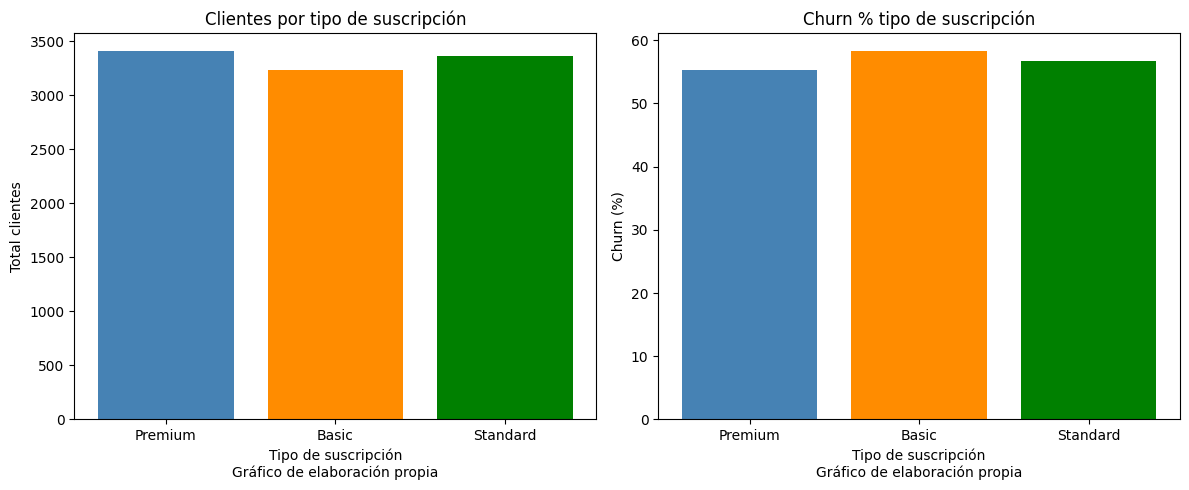

In [69]:
# Importamos la librería que nos permite pintar los resultados
import matplotlib.pyplot as plt

# Pasamos los resultados a tipo Pandas para poder visualizar los datos
resultado_suscripciones_pandas = resultado_suscripciones.toPandas()

# Creamos una malla de dos columnas y una fila para ver los gráficos fácilmente
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# El primer gráfico de barras muestra el total de clientes de cada tipo de suscripcion
ax1.bar(resultado_suscripciones_pandas["Subscription Type"], resultado_suscripciones_pandas["total_clientes"], color=["steelblue", "darkorange", "green"])
ax1.set_title("Clientes por tipo de suscripción")
ax1.set_xlabel("Tipo de suscripción\nGráfico de elaboración propia")
ax1.set_ylabel("Total clientes")

# El segundo muestra el % de Yes en el campo Churn_YesNo
ax2.bar(resultado_suscripciones_pandas["Subscription Type"], resultado_suscripciones_pandas["churn_%"], color=["steelblue", "darkorange", "green"])
ax2.set_title("Churn % tipo de suscripción")
ax2.set_xlabel("Tipo de suscripción\nGráfico de elaboración propia")
ax2.set_ylabel("Churn (%)")

plt.tight_layout()
plt.show()

1. En la primera gráfica observamos los tres segmentos están equilibrados, lo que indica que no hay un tipo de suscripción que domine sobre otro. Esto sugiere que la empresa tiene una base de clientes diversificada, lo cual podría indicar que, o bien los precios de las tarifas son similares o las prestaciones son muy parecidas. El objetivo sería aumentar el valor de la tarifa premium y llevar más clientes a dicha tarifa.

2. Los tres planes tienen un churn altísimo, por encima del 50% tal y como habíamos comentado anteriormente. Esto sugiere un problema estructural de compañía ya que el % de abandonos es muy alto en todas las suscripciones. Lo más preocupante es que el % de abandonos en la categoría premium es sumamente alto, lo que indica que el valor del producto no es bueno o no acaba de encajar con el público en general, lo cual encaja con la primera conclusión que hemos inferido del gráfico *1*.

La prioridad no debería ser mover clientes de suscripción Basic a Premium, sino entender por qué se van todos y conseguir la fidelización de los clientes a lo largo del tiempo. Y el segundo objetivo sería obtener una clara diferenciación entre tarifas y conseguir más clientes premium.

Por otro lado, vamos a realizar el mismo análisis para la duración del contrato:


In [70]:
# Total clientes por duración de contrato
total_contrato = sdf_customer_churn.groupBy("Contract Length").agg(count("*").alias("total_clientes"))

# Churn % por duración de contrato
churn_contrato = sdf_customer_churn.groupBy("Contract Length").agg(round(100*count(when(col("Churn_YesNo") == "Yes", 1))/count("*"), 2).alias("churn_%"))

# Unimos ambos resultados y mostramos en pantalla
resultado_contrato = total_contrato.join(churn_contrato, on="Contract Length")
resultado_contrato.show()

+---------------+--------------+-------+
|Contract Length|total_clientes|churn_%|
+---------------+--------------+-------+
|         Annual|          4046|  45.06|
|      Quarterly|          3970|  46.98|
|        Monthly|          1984|  100.0|
+---------------+--------------+-------+



Podemos observar en este caso que los clientes con la longitud del contrato *Annual* o *Quarterly* es inferior al 50%, sin embargo está muy cercano.
Por otro lado, es muy alarmante que para la longitud *Monthly* tengamos un % del campo *Churn_YesNo* del 100%, esto indica que el producto tiene demasiadas deficiencias.

Vamos a pintar los resultados

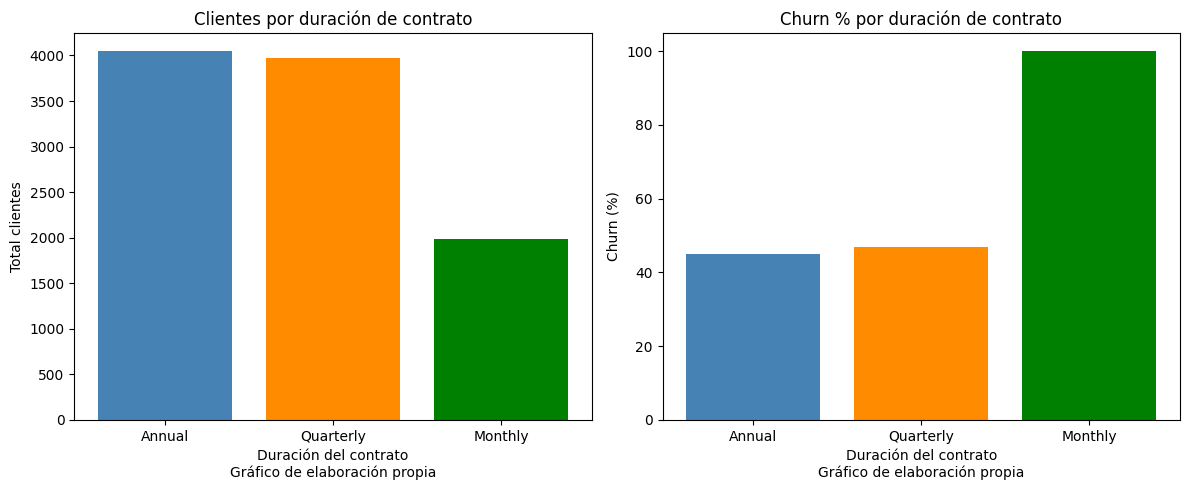

In [71]:
# Pasamos los datos necesarios a Pandas
resultado_contrato_pd = resultado_contrato.toPandas()

# Creamos la malla para visualizar los datos en la misma fila
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Pintamos el total de clientes por duración de contrato
ax1.bar(resultado_contrato_pd["Contract Length"], resultado_contrato_pd["total_clientes"], color=["steelblue", "darkorange", "green"])
ax1.set_title("Clientes por duración de contrato")
ax1.set_xlabel("Duración del contrato\nGráfico de elaboración propia")
ax1.set_ylabel("Total clientes")

# Pintamos el % de churn por duración de contrato
ax2.bar(resultado_contrato_pd["Contract Length"], resultado_contrato_pd["churn_%"], color=["steelblue", "darkorange", "green"])
ax2.set_title("Churn % por duración de contrato")
ax2.set_xlabel("Duración del contrato\nGráfico de elaboración propia")
ax2.set_ylabel("Churn (%)")

plt.tight_layout()
plt.show()

Nuevamente vamos a hablar sobre las implicaciones profesionales que tienen los resultados de los gráficos:

1. Los contratos anuales y de quarterly son mucho mayores, lo cual es de elogiar ya que han conseguido que el número de clientes que contratan en mayor longitud sea superior a los que contratan por corta duración. Sin embargo, el número de clientes que contratan mensualmente es alto y deberían de convertirse a quarterly y los de quarterly a anuales.

2. Este gráfico es preocupante ya que indica nuevamente que el producto no es interesante ya que los que tienen posibilidad de salirse de la suscripción al mes lo aprovecha y se salen, lo que indica nuevamente que la fidelización no es la adecuada.

De estos gráficos se elogia el marketing inicial que logra convertir a clientes de larga duración y critica el producto ya que no es lo suficientemente bueno como para que no abandonen.


---

## IV. Análisis descriptivo con PySpark

Nos piden calcular la media y la mediana de todos los conjuntos de datos salvo de *CustomerID* que se considera numérica.

Para hacer este tipo de análisis lo primero es asegurarse de que no hayan datos nulos o faltantes en nuestros datos. Por lo tanto vamos a calcular por cada conjunto de datos cuantos missing tenemos:


In [72]:
# Mostrar el conteo de valores nulos por columna en el DataFrame de PySpark
sdf_customer_churn.select([count(when(col(c).isNull(), c)).alias(c) for c in sdf_customer_churn.columns]).show()

+----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+
|CustomerID|Age|Gender|Tenure|Usage Frequency|Support Calls|Payment Delay|Subscription Type|Contract Length|Total Spend|Last Interaction|Churn_YesNo|
+----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+
|         0|  0|     0|     0|              0|            0|            0|                0|              0|          0|               0|          0|
+----------+---+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+



Esto simplifica la tarea ya que como observamos, no hay ningún missing en ninguna de las columnas de nuestros datos.

En este punto tenemos dos opciones:

  **1.** Quitar todas las variables categóricas de nuestro análisis y calcular de manera simplificada los estadísticos mencionados.

  **2.** Hacer una conversión de los datos categóricos que nos interesan para poder hacer un cálculo de los estadísticos.

En este caso, tenemos muchas variables categóricas que nos pueden ser de gran utilidad para más adelante, como bien pueden ser *Contract Lenght*, *Subscription Type* o *Churn_YesNo*, por lo tanto, vamos a hacer una transformación de los datos en donde podremos interpretar la información categórica como numérica.


In [73]:
# Importamos todas las funciones necesarias
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType
from pyspark.ml.feature import StringIndexer, VectorAssembler
from pyspark.ml import Pipeline

# Separamos los tipos de las columnas
"""
En esta sección vamos a separar todos los datos de la mejor manera posible,
es decir, vamos a separar CustomerID como una variable totalmente separada
ya que se nos indica que no la podemos meter en nuestro análisis,
guardamos las columnas de tipo string, las columnas de tipo numéricas
y por último, la variable objetivo del futuro modelo que plantearemos.
"""
Customer_ID = "CustomerID"
str_cols = ["Gender", "Subscription Type", "Contract Length"]
label_col = "Churn_YesNo"
float_cols = ["Age", "Tenure", "Usage Frequency", "Support Calls", "Payment Delay", "Total Spend", "Last Interaction"]

"""
Podríamos verificar que todas las columnas de tipo numérico son de tipo
DoubleType, pero ya nos seguramos de eso all inicio del proyecto
"""

# Creamos un StringIndexer por cada columna string predictora
idx = [StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in str_cols]

# Indexamos la variable objetivo por separado
label_indexer = StringIndexer(inputCol=label_col, outputCol="Churn_YesNo_Labeled", handleInvalid="keep")

# Aplicamos el pipeline completo
pipeline = Pipeline(stages= idx + [label_indexer])
sdf_idx = pipeline.fit(sdf_customer_churn).transform(sdf_customer_churn)

# Mostramos el nuevo dataframe
sdf_idx.show(5)

+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+----------+---------------------+-------------------+-------------------+
|CustomerID| Age|Gender|Tenure|Usage Frequency|Support Calls|Payment Delay|Subscription Type|Contract Length|Total Spend|Last Interaction|Churn_YesNo|Gender_idx|Subscription Type_idx|Contract Length_idx|Churn_YesNo_Labeled|
+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+----------+---------------------+-------------------+-------------------+
|  314921.0|36.0|  Male|  10.0|           14.0|          1.0|         20.0|         Standard|         Annual|     736.02|            27.0|         No|       0.0|                  1.0|                0.0|                1.0|
|  401716.0|40.0|  Male|  20.0|           23.0|          4.0|          6.0|         Standard|      Quart

Añadimos la columna de *Features* para un posible futuro.

In [74]:
# Columnas indexadas (solo las predictoras)
indexed_cols = [c + "_idx" for c in str_cols]

# Features finales = numéricas + indexadas (sin la label)
features = float_cols + indexed_cols

# VectorAssembler con todas las features
vector_assembler = VectorAssembler(inputCols=features, outputCol="features")
sdf_features = vector_assembler.transform(sdf_idx)

sdf_features.show(5)

+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+----------+---------------------+-------------------+-------------------+--------------------+
|CustomerID| Age|Gender|Tenure|Usage Frequency|Support Calls|Payment Delay|Subscription Type|Contract Length|Total Spend|Last Interaction|Churn_YesNo|Gender_idx|Subscription Type_idx|Contract Length_idx|Churn_YesNo_Labeled|            features|
+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+----------+---------------------+-------------------+-------------------+--------------------+
|  314921.0|36.0|  Male|  10.0|           14.0|          1.0|         20.0|         Standard|         Annual|     736.02|            27.0|         No|       0.0|                  1.0|                0.0|                1.0|[36.0,10.0,14.0,1...|
|  401716.0|40.0|  M

Vamos a calcular los estadísticos necesarios:

In [75]:
# Metemos en un dataframe toda la información necesaria
sdf_stats = sdf_features.drop("CustomerID","Gender","Subscription Type","Contract Length", "Churn_YesNo", "features").describe()

# Mostramos los resultados
sdf_stats.show()

+-------+------------------+-----------------+-----------------+------------------+-----------------+------------------+-----------------+-------------------+---------------------+-------------------+-------------------+
|summary|               Age|           Tenure|  Usage Frequency|     Support Calls|    Payment Delay|       Total Spend| Last Interaction|         Gender_idx|Subscription Type_idx|Contract Length_idx|Churn_YesNo_Labeled|
+-------+------------------+-----------------+-----------------+------------------+-----------------+------------------+-----------------+-------------------+---------------------+-------------------+-------------------+
|  count|             10000|            10000|            10000|             10000|            10000|             10000|            10000|              10000|                10000|              10000|              10000|
|   mean|           39.2613|          30.9536|          15.7726|            3.5932|          13.0305| 633.3173110000

Vamos a quedarnos únicamente con las filas que nos piden en el problema. Para ello filtraremos solamente por la media y la desviación estandar y haremos una transpocisión de la matriz para una visualización más llamativa.

Pasaremos simplemente la columna de resultados a pandas para poder hacer la traspuesta fácilmente ya que operar con matrices en PySpark se vuelve un poco más tedioso y solamente buscamos la fácil visualización.

In [76]:
# Filtramos solo mean y stddev y transponemos
sdf_stats = sdf_features.drop("CustomerID", "Gender", "Subscription Type", "Contract Length", "Churn_YesNo", "features").describe()

# Filtramos las filas de mean y stddev
sdf_mean_std = sdf_stats.filter(F.col("summary").isin(["mean", "stddev"]))

# Convertimos a pandas para transponer fácilmente
pdf = sdf_mean_std.toPandas()

# Transponemos: las columnas pasan a ser filas, y mean/stddev se convierten en columnas
pdf_T = pdf.set_index("summary").T.reset_index()
pdf_T.columns = ["feature", "mean", "stddev"]

# Convertimos las columnas a float para mejor visualización
pdf_T["mean"] = pdf_T["mean"].astype(float).round(4)
pdf_T["stddev"] = pdf_T["stddev"].astype(float).round(4)

print(pdf_T.to_string(index=False))

              feature     mean   stddev
                  Age  39.2613  12.4925
               Tenure  30.9536  17.1379
      Usage Frequency  15.7726   8.6314
        Support Calls   3.5932   3.0797
        Payment Delay  13.0305   8.2619
          Total Spend 633.3173 240.4718
     Last Interaction  14.4916   8.6211
           Gender_idx   0.4333   0.4956
Subscription Type_idx   0.9827   0.8147
  Contract Length_idx   0.7938   0.7487
  Churn_YesNo_Labeled   0.4328   0.4955


Podemos observar que contamos con 10000 registros sin valores nulos ni missings. Dado que vamos a obtener información numérica tenemos que excluir de dicho análisis las variables categóricas, es decir, excluimos *CustomerID*, *Gender*, *Subscription Type*, *Contract Length* y *Churn_YesNo*.

Vamos a hacer un análisis en profundidad del significado de estos estadísticos:

1. ***Age*:** La edad media es de 39.26 años con una desviación estándar de 12.49. Esto significa que los consumidores se distribuyen entre los 18 y 65 años según el mínimo y el máximo. La dispersión es relativamente baja lo que nos indica que los clientes son adultos, lo que nos sugiere o bien que el producto está orientado a adultos. La distribución de los datos podría ajustarse a una t-student, que es similar a una normal, pero con el punto medio un poco desviado.

2. ***Tenure*:** La media es de 30.95 meses con un máximo de 60 y una desviación de 17.14. El rango completo es de 1 a 60, por lo que está bien representado, indicando heterogeneidad en la base de clientes, que se corresponde con recién incorporados y clientes de largo plazo. Tenemos una desviación relativamente elevada relativa a la media lo que sugiere una alta variabilidad en la fidelización. Podríamos afirmar a priori que los datos se corresponden con una distribución normal (tras normalizar datos).

3. ***Usage Frequency*:** La media es de 15.77 sobre un máximo de 30, con desviación típica de 8.63. La distribución parece simétrica alrededor de la media ya que el punto medio es 15.50, lo que podría indicar una distribución uniforme o aproximadamente normal (tras normalizar los datos). El mínimo es 1, lo que nos indica que no existen cuentas inactivas.

4. ***Support Calls*:** Tenemos una media de 3.59 llamadas con un mínimo de 0 y máximo de 10. La desviación es de 3.08, lo que es alta respecto a la media, lo que indica que existen clientes con alta demanda de soporte. Esta variable nos indica que el producto tiene problemas o que es difícil de usar, lo cual nos puede dar una idea de la variable churn y merece especial atención a la hora del paso de aprendizaje (variable a incluir en el modelo).

5. ***Payment Delay*:** La media es de 13.03 días con una desviación de 8.62 con un rango de 0 a 30. El hecho de que la media esté cerca del punto medio que es 15 y la desviación sea considerable sugiere que hay una variabilidad no despreciable en el comportamiento del pago. Los valores cercanos a 0 representan clientes puntuales, mientras que valores próximos a 30 son señales claras de riesgo de churn. Esta es otra variable que deberemos tener en cuenta a la hora del modelo de predicción.

6. ***Total Spend*:** Es la variable con mayor varianza y una media de 633.3. Tenemos un rango de 100 a 1000. El coeficiente de variación indica dispersión alta y la amplitud del rango sugiere diferencias notables en los planes o en el tiempo de permanencia.

7. ***Last Interaction*:** La media es de 14.49 días con una desviación de 8.62, y un rango de 1 a 30. La media está cerca al punto medio del rango y la desviación estándar es elevada, lo que indica una distribución amplia. Esto significa que hay clientes con valores altos de 20 días sin interacción lo que representa un segmento en riesgo de abandono.

8. ***Gender_idx*:** La media es de 0.43 con una desviación de 0.50. Al ser una variable binaria indexada (0 o 1), la media representa la proporción de una de las categorías, en este caso indica que aproximadamente el 43% de los clientes pertenecen a una categoría y el 57% a la otra. La desviación cercana a 0.50 es característica de variables binarias y confirma que la distribución está relativamente equilibrada entre ambos géneros.

9. ***Subscription Type_idx*:** Con una media de 0.98 y desviación de 0.81, esta variable tiene tres categorías indexadas (0, 1, 2). La media cercana a 1 indica que los valores se distribuyen de forma relativamente homogénea entre los tres tipos de suscripción. La desviación de 0.81 refleja la variabilidad esperada en una variable con más de dos categorías.

10. ***Contract Length_idx*:** La media es de 0.79 con una desviación de 0.75, también con tres categorías indexadas. La media por debajo de 1 sugiere que la categoría 0 (la más frecuente según el criterio de StringIndexer, que ordena por frecuencia) predomina ligeramente. Podría ser relevante en el modelo ya que el tipo de contrato está directamente relacionado con la permanencia y el riesgo de churn.

11. ***Churn_YesNo_Labeled*:** La media es de 0.43 con una desviación de 0.50, lo que nos indica que aproximadamente el 43% de los clientes han abandonado el servicio.
Al ser nuestra variable objetivo, este valor es especialmente relevante ya que nos indica un dataset relativamente equilibrado, lo que es favorable para el entrenamiento del modelo y reduce el riesgo de sesgo hacia la clase mayoritaria.

---

## V. Análisis de correlación

Salvo la variable CustomerID que se ha pedido que no se introduzca en el modelo, todas las demás podemos hacer uso de ellas y utilizarlas para enriquecer el modelo si cuentan con una correlación adecuada.

Ahora estamos en posición de poder calcular la correlación como sigue:

In [77]:
# Cargamos las librerías necesarias para calcular la correlación
from pyspark.ml.stat import Correlation
import pandas as pd

features2 = float_cols + indexed_cols + ["Churn_YesNo_Labeled"]

# Creamos un nuevo assembler
"""
El motivo de esta decisión es que nos interesa saber como se relacionan
las variables con Churn_YesNo, por tanto la incluimos en este punto, pero para cálculos
posteriores seguiremos con la establecida anteriormente
"""
assembler_for_corr = VectorAssembler(inputCols=features2, outputCol="all_features_vector")
sdf_with_all_features = assembler_for_corr.transform(sdf_idx)

# Calcular la matriz de correlación con el método de "pearson"
corr_matrix = Correlation.corr(sdf_with_all_features, "all_features_vector", method="pearson")

# Extraer la matriz como array
corr_array = corr_matrix.collect()[0][0].toArray()

# Convertir a DataFrame de pandas para mejor visualización
corr_df = pd.DataFrame(corr_array, index=features2, columns=features2)

corr_df

,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Gender_idx,Subscription Type_idx,Contract Length_idx,Churn_YesNo_Labeled
Age,1.000000,-0.000693,-0.004411,0.175940,0.053811,-0.076583,0.033162,0.034406,0.014163,0.083979,-0.226358
Tenure,-0.000693,1.000000,-0.031740,-0.018698,0.007875,0.013821,0.002084,-0.005193,0.035615,-0.020832,0.053986
Usage Frequency,-0.004411,-0.031740,1.000000,-0.032477,-0.033654,0.029837,-0.010357,-0.013086,-0.003305,-0.015196,0.066370
Support Calls,0.175940,-0.018698,-0.032477,1.000000,0.164219,-0.225403,0.073694,0.096899,0.010509,0.172423,-0.578483
Payment Delay,0.053811,0.007875,-0.033654,0.164219,1.000000,-0.122547,0.044035,0.063189,-0.004424,0.115537,-0.317328
Total Spend,-0.076583,0.013821,0.029837,-0.225403,-0.122547,1.000000,-0.062719,-0.068477,-0.020887,-0.120416,0.423405
Last Interaction,0.033162,0.002084,-0.010357,0.073694,0.044035,-0.062719,1.000000,-0.130931,0.003504,0.055528,-0.150066
Gender_idx,0.034406,-0.005193,-0.013086,0.096899,0.063189,-0.068477,-0.130931,1.000000,-0.016112,0.072366,-0.184639
Subscription Type_idx,0.014163,0.035615,-0.003305,0.010509,-0.004424,-0.020887,0.003504,-0.016112,1.000000,0.023338,-0.024560
Contract Length_idx,0.083979,-0.020832,-0.015196,0.172423,0.115537,-0.120416,0.055528,0.072366,0.023338,1.000000,-0.358711


Vamos a pintar los resultados en un mapa de calor para identificar con mayor facilidad:

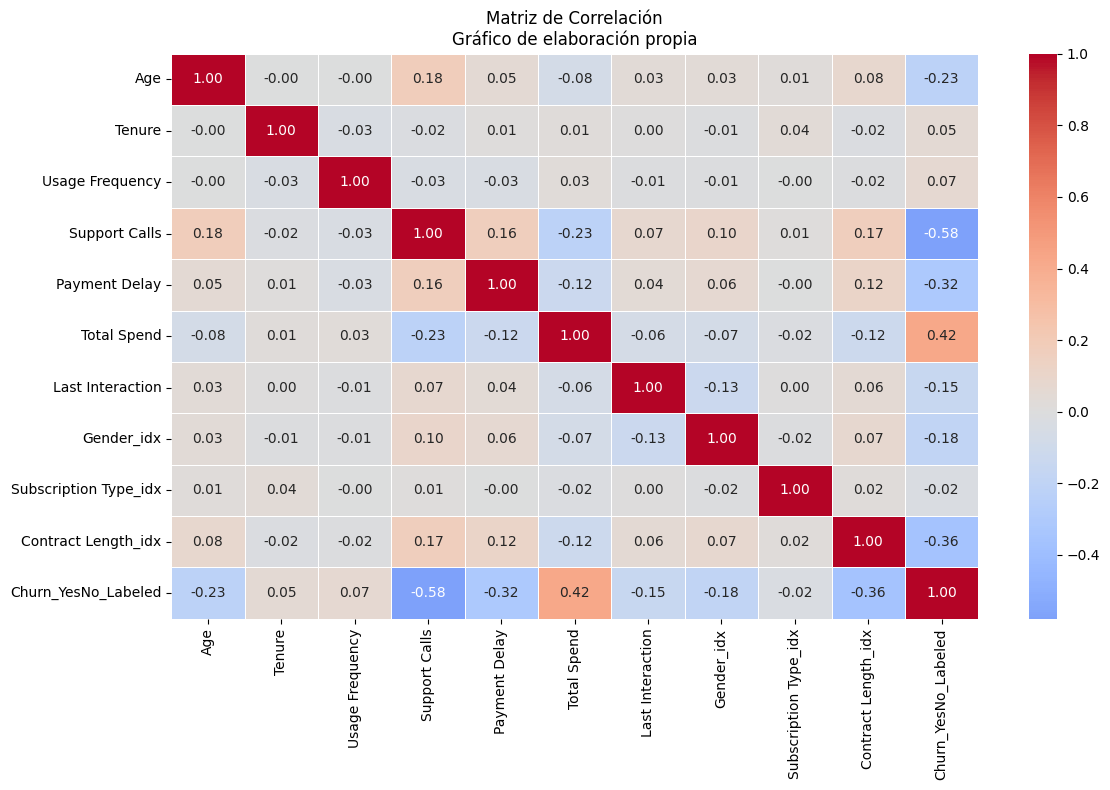

In [78]:
# Importamos las librerías para pintar la matriz de correlación como un mapa de calor
import seaborn as sns

# Establecemos el mapa de calor y lo pintamos
plt.figure(figsize=(12, 8))
sns.heatmap(corr_df, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Matriz de Correlación\nGráfico de elaboración propia")
plt.tight_layout()
plt.show()

El análisis de la matriz de correlación revela que la variable *Churn_YesNo* tiene las correlaciones más altas del conjunto de datos. La correlación negativa más fuerte se da con la variable *Support Calls* con un valor de -0.58, lo que significa que, a mayor número de llamadas para obtener soporte, existe una mayor probabilidad de abandono del servicio, lo que nos indica una experiencia insatisfactoria por parte del cliente. Esto es un predictor clave de la variable *Churn_YesNo*.

Las siguientes más altas son *Contract Length* con un valor -0.36 y *Payment Delay* con un valor de -0.32, donde los contratos más largos actúan como un factor que retiene a los clientes y los retrasos en el pago como señal de riesgo de abandono del servicio.

Por último, con una correlación positiva tenemos la variable *Total Spend* con un valor de 0.42, que nos muestra que los clientes que más gastan tienen mayor tendencia a dejar el servicio, lo cual puede indicar una percepción de precio elevado respecto al valor percibido.

El resto de las variables presentan correlaciones débiles entre sí y por tanto una buena independencia entre predictores. Destaca que las variables *Age*, *Tenure, Usage Frequency* o *Subscription Type* tienen correlaciones muy cercanas a 0 con respecto a la variable *Churn_YesNo*, lo que indica que no son factores que determinen el abandono por sí solos.

El modelo predictivo que realizaremos debería priorizar las variables *Support Calls*, *Contract Length*, *Payment Delay* y *Total Spend* como las variables con mayor poder explicativo sobre la variable objetivo que es *Churn_YesNo*.


---

## VI. Selección del modelo predictivo

Tras todo el análisis que hemos realizado anteriormente, el modelo que vamos a elegir es el **Random Forest**. El motivo es el siguiente:

Planteamos un problema de la predicción del abandono de los clientes, es decir, la variable *Churn_YesNo*.

El modelo Random Forest es el adecuado porque el comportamiento de los clientes suele depender de múltiples variables como el tipo de suscripción, la duración del contrato, la frecuencia del uso del producto, el historial de pagos o interacciones con soporte. Todas estas características cuyas relaciones con la decisión de abandonar no suelen ser lineales lo que dificultaría el uso de modelos como la recta de regresión lineal básica. Dentro del Machine Learning, el Random Forest combina múltiples árboles de decisión entrenados sobre diferentes subconjuntos de datos y variables, lo que permite capturar patrones complejos y reducir el riesgo de sobreajuste típico de un único árbol, por tanto, el modelo tiene una alta capacidad predictiva incluso cuando los datos contienen ruido o interacciones entre variables difíciles de modelar explícitamente. Dicho lo anterior, llegamos a la conclusión de que es una herramienta eficaz para identificar con anticipación qué clientes presentan mayor probabilidad de abandonar el servicio y así permitir a la empresa implementar estrategias de retención basadas en datos.

### 6.1 Selección del modelo predictivo (con sklearn)

Vamos a escoger un random forest classifier de aprendizaje supervisado para estimar la variable Churn_YesNo.

In [79]:
# Definimos un nuevo y definitivo vector de características predictoras que incluiremos en nuestro modelo
features_def = ["Age","Tenure","Usage Frequency","Support Calls","Payment Delay","Total Spend","Last Interaction","Gender_idx","Subscription Type_idx","Contract Length_idx"]

# Mostramos el DataFrame para recordarlo
sdf_features.show()

+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+----------+---------------------+-------------------+-------------------+--------------------+
|CustomerID| Age|Gender|Tenure|Usage Frequency|Support Calls|Payment Delay|Subscription Type|Contract Length|Total Spend|Last Interaction|Churn_YesNo|Gender_idx|Subscription Type_idx|Contract Length_idx|Churn_YesNo_Labeled|            features|
+----------+----+------+------+---------------+-------------+-------------+-----------------+---------------+-----------+----------------+-----------+----------+---------------------+-------------------+-------------------+--------------------+
|  314921.0|36.0|  Male|  10.0|           14.0|          1.0|         20.0|         Standard|         Annual|     736.02|            27.0|         No|       0.0|                  1.0|                0.0|                1.0|[36.0,10.0,14.0,1...|
|  401716.0|40.0|  M

Dividimos los datos en train y test

In [80]:
# Importamos la librería que nos permite dividir los datos
from sklearn.model_selection import train_test_split

# Establecemos las features o características
X_classification = sdf_features.select(features_def).toPandas()
y_classification = sdf_features.select("Churn_YesNo_Labeled").toPandas().squeeze()

# Separamos los datos en train + test
X_train_cla, X_test_cla, y_train_cla, y_test_cla = train_test_split(X_classification, y_classification, test_size=0.2, random_state=1, stratify=y_classification)

Ahora vamos a crear el grid de parámetros para establecer las condiciones del entrenamiento de nuestro modelo que deberá seguir:

In [81]:
# Importamos todas las librerías necesarias para este modelo
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_curve,
    roc_auc_score
)
from sklearn.preprocessing import label_binarize

# Vamos a entrenar el modelo con el grid de parámetros asique lo definimos
grid_de_parametros_rf = {"n_estimators" : [50, 100],  #NÚMERO DE ÁRBOLES A ENTRENAR
                         "max_depth" : [5, 10, None]  #PROFUNDIDAD MÁXIMA DE CADA ÁRBOL
                        }

# Definimos el modelo
# Conjuntos de validación cruzada nos pedirá un número de conjuntos de validación cv
rf_gsc = GridSearchCV( RandomForestClassifier(random_state=1), grid_de_parametros_rf, cv = 5 ) # Le pasamos un modelo y confirmación de parámetros

rf_gsc

GridSearchCV(cv=5, estimator=RandomForestClassifier(random_state=1),
             param_grid={'max_depth': [5, 10, None], 'n_estimators': [50, 100]})

Nos queda ajustar el modelo a nuestrps datos y hacer las predicciones pertinentes. Luego calculamos las métricas principales y las mostramos.

In [82]:
# Ajustamos el modelo
rfm_cla = rf_gsc.fit(X_train_cla, y_train_cla)

# Predicciones
y_train_pred = rfm_cla.predict(X_train_cla)
y_test_pred = rfm_cla.predict(X_test_cla)

# Accuracy y precision
accuracy_train = accuracy_score(y_train_cla, y_train_pred)
accuracy_test = accuracy_score(y_test_cla, y_test_pred)

precision_train = precision_score(y_train_cla, y_train_pred, average='weighted')
precision_test = precision_score(y_test_cla, y_test_pred, average='weighted')

print("Métricas:")
print(f"Train: {accuracy_train:.4f}, Precision: {precision_train:.4f}")
print(f"Test: {accuracy_test:.4f}, Precision: {precision_test:.4f}")

Métricas:
Train: 1.0000, Precision: 1.0000
Test: 0.9940, Precision: 0.9940


El modelo Random Forest obtenido tras el GridSearchCV muestra resultados excelentes. En train alcanza un accuracy y precisión del 100%, mientras que en test obtiene un 99.40% en ambas métricas.

La pequeña diferencia entre train y test, que es de 0.60% indica que el modelo **no sufre overfitting**, generalizando muy bien a datos que no se le ha dejado observar en el entrenamiento. Un accuracy perfecto en train es esperable en Random Forest ya que los árboles se ajustan completamente a los datos de entrenamiento, pero lo verdaderamente relevante es el 99.40% en test, que confirma la solidez del modelo.


Vamos a calcular más ampliamente las métricas del modelo usando una plantilla obtenida durante el máster:

In [83]:
# Definimos una función que nos permite computar las métricas de clasificación
def compute_metrics(model, X_tr, y_tr, X_te, y_te):
    pred_train = model.predict(X_tr)
    pred_test = model.predict(X_te)
    acc_train = accuracy_score(y_tr, pred_train)
    acc_test = accuracy_score(y_te, pred_test)
    prec_train = precision_score(y_tr, pred_train, average='weighted')
    prec_test = precision_score(y_te, pred_test, average='weighted')
    rec_train = recall_score(y_tr, pred_train, average='weighted')
    rec_test = recall_score(y_te, pred_test, average='weighted')
    f1_train = f1_score(y_tr, pred_train, average='weighted')
    f1_test = f1_score(y_te, pred_test, average='weighted')
    return [acc_train, prec_train, rec_train, f1_train, acc_test, prec_test, rec_test, f1_test]

# Guardamos todos los resultados en un data frame
results = pd.DataFrame([compute_metrics(rfm_cla, X_train_cla, y_train_cla, X_test_cla, y_test_cla),],
                columns = ["Accuracy_train", "Precision_train", "Recall_train", "F1_train", "Accuracy_test", "Precision_test", "Recall_test", "F1_test"],
                index = ["Random Forest"])
results

,Accuracy_train,Precision_train,Recall_train,F1_train,Accuracy_test,Precision_test,Recall_test,F1_test
Random Forest,1.0,1.0,1.0,1.0,0.994,0.994011,0.994,0.994002


Los resultados muestran el rendimiento del **Random Forest** que hemos entrenado para la clasificación. En train, el modelo alcanza un Accuracy, Precision, Recall y F1-Score de 1.0, lo que significa que clasifica perfectamente los datos con los que fue entrenado. En test, todas las métricas son igualmente sólidas y muy próximas a 1.0, lo que indica que el modelo generaliza correctamente a datos que no ha observado durante el entrenamiento sin presentar sobreajuste.ento.

Para dar más detalles del comportamiento de nuestro modelo predictivo vamos a hacer uso de la función *classification_report* que nos amplía la información que ya poseemos.

In [84]:
# Reporte detallado por clase
print("\nClasificación de datos de Train")
print(classification_report(y_train_cla, y_train_pred))
print("\nClasificación de datos de Test")
print(classification_report(y_test_cla, y_test_pred))


Clasificación de datos de Train
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00      4538
         1.0       1.00      1.00      1.00      3462

    accuracy                           1.00      8000
   macro avg       1.00      1.00      1.00      8000
weighted avg       1.00      1.00      1.00      8000


Clasificación de datos de Test
              precision    recall  f1-score   support

         0.0       1.00      0.99      0.99      1134
         1.0       0.99      1.00      0.99       866

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



El reporte de clasificación por clase confirma los resultados que habíamos anticipado. En train el modelo clasifica perfectamente ambas clases (0 = no churn, 1 = churn) con precision, recall y f1-score de 1 en los 8000 registros de entrenamiento.

En test, sobre 2000 registros, los resultados son igualmente sólidos:

- **Clase 0 (No):** Precisión perfecta, de 1 con un recall de 0.99, lo que significa que prácticamente no hay falsos negativos, es decir, el modelo apenas clasifica clientes que no van a abandonar como si lo fueran a hacer.

- **Clase 1 (Yes):** Recall perfecto (1.00) con precisión de 0.99, lo que indica que el modelo detecta prácticamente todos los casos reales de churn, que es precisamente el objetivo más crítico del modelo.

El f1-score de 0.99 en ambas clases y el weighted average de 0.99 confirman que el modelo está bien calibrado y no presenta sesgo hacia ninguna de las dos clases, algo favorecido por el balance ya observado en la distribución de la variable objetivo.

Vamos a pintar la curva ROC

In [85]:
# Calculamos la matriz de confusión que nos permite ver los falsos positivos y los falsos negativos
from sklearn import metrics
cm = metrics.confusion_matrix(y_test_cla, y_test_pred)
cm

array([[1126,    8],
       [   4,  862]])

In [86]:
# Calculamos la métrica usando probabilidades de la clase positiva
y_proba = rfm_cla.predict_proba(X_test_cla)[:, 1]
auc_roc = metrics.roc_auc_score(y_test_cla, y_proba)
auc_roc

np.float64(0.999899698995157)

In [87]:
# Importamos la librería que nos calcula la métrica para comparar
from sklearn.metrics import roc_curve, auc

false_positive_rate, true_positive_rate, thresholds = roc_curve(y_test_cla, y_proba)
roc_auc = auc(false_positive_rate, true_positive_rate)
roc_auc

np.float64(0.999899698995157)

Text(0.5, 0, 'False Positive Rate')

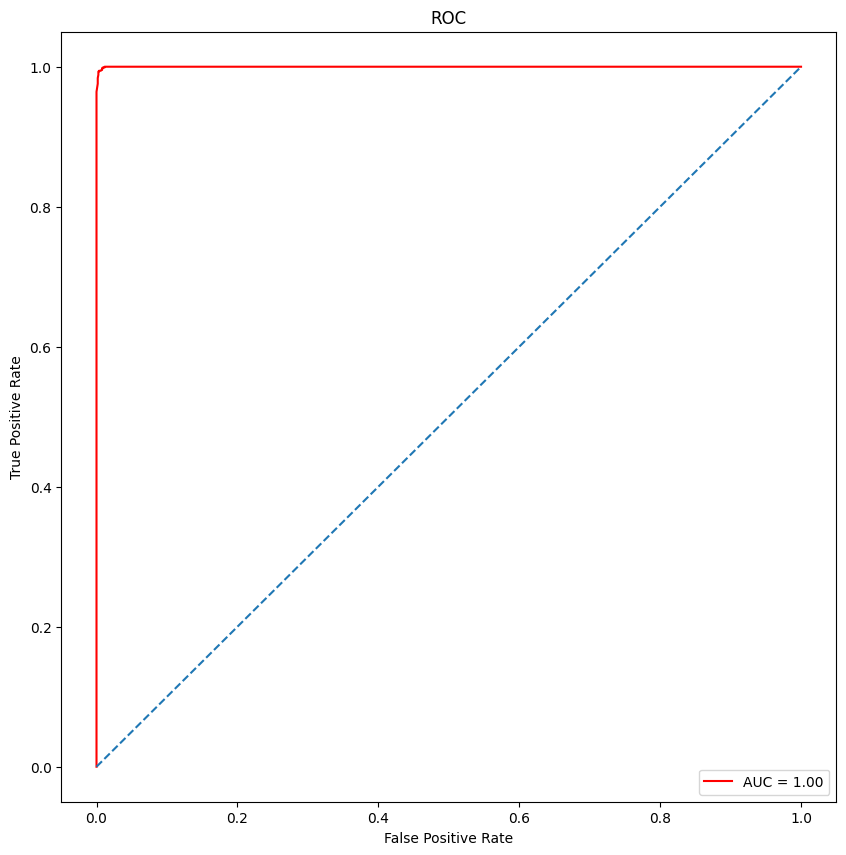

In [88]:
# Pintamos la curva ROC
plt.figure(figsize=(10,10))
plt.title('ROC')
plt.plot(false_positive_rate, true_positive_rate, color='red', label = 'AUC = %0.2f' % roc_auc)
plt.legend(loc = 'lower right')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.axis('tight')
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')

La curva ROC muestra que el modelo clasifica muy bien entre las dos clases. Además, el AUC = 0.99 indica que el modelo tiene una capacidad de predicción casi perfecta, muy superior a la de un clasificador aleatorio. Esto nos podría llevar a pensar que hemos tenido un overfitting, pero verificamos que tanto en train como en test las métricas son igual de altas, lo que nos demuestra que nuestro modelo ajusta perfectamente sin sobreentrenamiento.


### 6.2 Selección del modelo predictivo (con PySpark MLlib)

Resolvemos nuevamente el problema indicado pero con la librería MLlib de PySpark. Al final del punto observaremos que este método es más fiable ya que la curva ROC final se ajusta más a la realidad (tiene una major representación)

In [89]:
# Cargamos las librerías
from pyspark.ml.classification import RandomForestClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.sql.functions import udf
from pyspark.sql import Row
from pyspark.sql.types import FloatType

In [90]:
# Preparamos las columnas numéricas
float_cols = ["Age", "Tenure", "Usage Frequency", "Support Calls", "Payment Delay", "Total Spend", "Last Interaction"]

for col_name in float_cols: sdf_customer_churn = sdf_customer_churn.withColumn( col_name, col(col_name).cast(DoubleType()) )

# Preparamos las columnas tipo cat
str_feature_cols = ["Gender", "Subscription Type", "Contract Length"]

feature_indexers = [ StringIndexer(inputCol=c, outputCol=c + "_idx", handleInvalid="keep") for c in str_feature_cols ]
label_indexer = StringIndexer( inputCol="Churn_YesNo", outputCol="Churn_YesNo_idx", handleInvalid="keep" )

In [91]:
feature_cols = float_cols + ["Gender_idx", "Subscription Type_idx", "Contract Length_idx"]

# Aplicamos el ensamblador para juntarlas
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

# Establecemos el modelo del RF
rf = RandomForestClassifier(featuresCol="features", labelCol="Churn_YesNo_idx", seed=1 )

# Definimos el pipeline
pipeline = Pipeline(stages=feature_indexers + [label_indexer, assembler, rf])

# Dividimos en train y test
train_data, test_data = sdf_customer_churn.randomSplit([0.8, 0.2], seed=1)

In [92]:
# Creamos el grid
param_grid = (ParamGridBuilder()
    .addGrid(rf.numTrees, [50, 100])
    .addGrid(rf.maxDepth, [5, 10])
    .build())

# Usamos MulticlassClassificationEvaluator en el CrossValidator
evaluator_cv = MulticlassClassificationEvaluator( labelCol="Churn_YesNo_idx", predictionCol="prediction", metricName="accuracy")
cv = CrossValidator( estimator=pipeline, estimatorParamMaps=param_grid, evaluator=evaluator_cv, numFolds=5, seed=1)

In [93]:
# Entrenamos el modelo
cv_model = cv.fit(train_data)
best_model = cv_model.bestModel

# Parámetros del mejor modelo
rf_best = best_model.stages[-1]
print(f"Best numTrees: {rf_best.getOrDefault(rf.numTrees)}")
print(f"Best maxDepth: {rf_best.getOrDefault(rf.maxDepth)}")

Best numTrees: 100
Best maxDepth: 10


Este tipo de entrenamiento (con PySpark) da resultados más fiables, pero el entrenamiento es notablemente más lento.

In [94]:
# Mostramos las predicciones
predictions_train = best_model.transform(train_data)
predictions_test  = best_model.transform(test_data)

In [95]:
# Calculamos el AUC con probabilidades para evitar incompatibilidades del BinaryClassificationEvaluator
get_prob_1 = udf(lambda v: float(v[1]), FloatType())

predictions_train_roc = predictions_train.withColumn("prob_1", get_prob_1(col("probability")))
pdf_roc_train = predictions_train_roc.select("Churn_YesNo_idx", "prob_1").toPandas()
fpr_train, tpr_train, _ = roc_curve(pdf_roc_train["Churn_YesNo_idx"], pdf_roc_train["prob_1"])
auc_train = auc(fpr_train, tpr_train)

predictions_test_roc = predictions_test.withColumn("prob_1", get_prob_1(col("probability")))
pdf_roc_test = predictions_test_roc.select("Churn_YesNo_idx", "prob_1").toPandas()
fpr_test, tpr_test, _ = roc_curve(pdf_roc_test["Churn_YesNo_idx"], pdf_roc_test["prob_1"])
auc_test = auc(fpr_test, tpr_test)

# Accuracy
evaluator_acc = MulticlassClassificationEvaluator( labelCol="Churn_YesNo_idx", predictionCol="prediction", metricName="accuracy")

acc_train = evaluator_acc.evaluate(predictions_train)
acc_test  = evaluator_acc.evaluate(predictions_test)

# Precision
evaluator_prec = MulticlassClassificationEvaluator( labelCol="Churn_YesNo_idx", predictionCol="prediction", metricName="weightedPrecision")

prec_train = evaluator_prec.evaluate(predictions_train)
prec_test  = evaluator_prec.evaluate(predictions_test)

# Recall
evaluator_rec = MulticlassClassificationEvaluator( labelCol="Churn_YesNo_idx", predictionCol="prediction", metricName="weightedRecall")

rec_train = evaluator_rec.evaluate(predictions_train)
rec_test  = evaluator_rec.evaluate(predictions_test)

# F1
evaluator_f1 = MulticlassClassificationEvaluator( labelCol="Churn_YesNo_idx", predictionCol="prediction", metricName="f1")

f1_train = evaluator_f1.evaluate(predictions_train)
f1_test  = evaluator_f1.evaluate(predictions_test)

"""
Pintamos solo 4 decimales del resultado
"""

columns = [
    Row(Métrica="AUC (ROC)", Train=float(auc_train), Test=float(auc_test)),
    Row(Métrica="Accuracy",  Train=float(acc_train),  Test=float(acc_test)),
    Row(Métrica="Precision", Train=float(prec_train), Test=float(prec_test)),
    Row(Métrica="Recall",    Train=float(rec_train),  Test=float(rec_test)),
    Row(Métrica="F1-Score",  Train=float(f1_train),   Test=float(f1_test))
]

sdf_metrics = spark.createDataFrame(columns)
sdf_metrics = sdf_metrics.withColumn("Train", F.round(F.col("Train"), 4)).withColumn("Test", F.round(F.col("Test"), 4))
sdf_metrics.show()

+---------+------+------+
|  Métrica| Train|  Test|
+---------+------+------+
|AUC (ROC)|0.9999|0.9995|
| Accuracy| 0.993| 0.988|
|Precision|0.9931|0.9883|
|   Recall| 0.993| 0.988|
| F1-Score| 0.993| 0.988|
+---------+------+------+



In [96]:
# Verificamos si hay alguna feature que sea prescindible
feature_importances = rf_best.featureImportances.toArray()

importance_df = sorted( zip(feature_cols, feature_importances), key=lambda x: x[1], reverse=True)

print("\nVar: ")
for fname, imp in importance_df:
    print(f"  {fname:<35} {imp:.4f}")


Var: 
  Support Calls                       0.3190
  Total Spend                         0.2104
  Contract Length_idx                 0.1483
  Age                                 0.1315
  Payment Delay                       0.1236
  Gender_idx                          0.0319
  Last Interaction                    0.0307
  Tenure                              0.0022
  Usage Frequency                     0.0016
  Subscription Type_idx               0.0008


Como podemos observar:

- Usage Frequency 0.0017
- Subscription Type_idx 0.0007

No contribuyen mucho al modelo, por lo que podríamos prescindir de esas variables.


In [97]:
# Pintamos la matriz de confusión
print("\n Matriz de confusión para el Test")
confusion = (predictions_test.groupBy("Churn_YesNo_idx", "prediction").count().orderBy("Churn_YesNo_idx", "prediction"))
confusion.show()


 Matriz de confusión para el Test
+---------------+----------+-----+
|Churn_YesNo_idx|prediction|count|
+---------------+----------+-----+
|            0.0|       0.0| 1157|
|            0.0|       1.0|   24|
|            1.0|       1.0|  815|
+---------------+----------+-----+



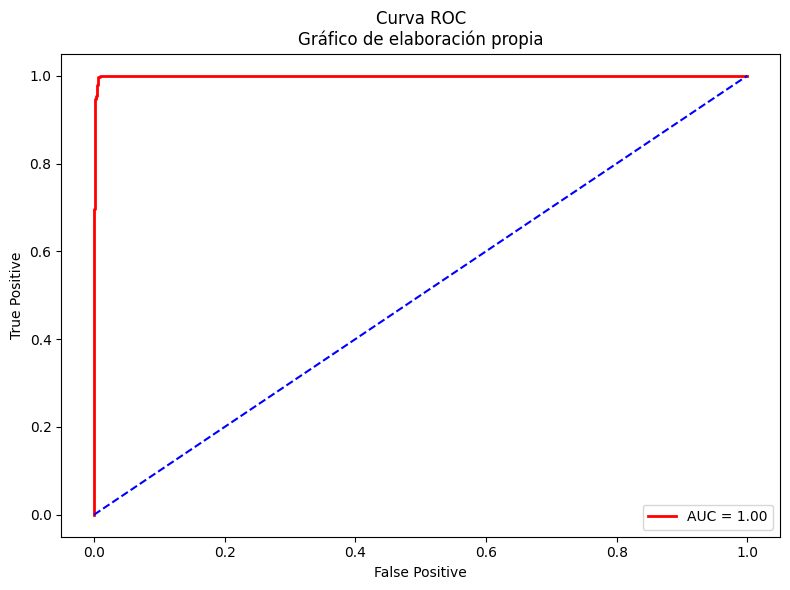

In [98]:
# Calculamos la curva roc
get_prob_1 = udf(lambda v: float(v[1]), FloatType())

predictions_test_roc = predictions_test.withColumn("prob_1", get_prob_1(col("probability")))

# Pasamos a pandas solo para pintar la curva
pdf_roc = predictions_test_roc.select("Churn_YesNo_idx", "prob_1").toPandas()

from sklearn.metrics import auc as sklearn_auc

fpr, tpr, _ = roc_curve(pdf_roc["Churn_YesNo_idx"], pdf_roc["prob_1"])
roc_auc = sklearn_auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color="red", linewidth=2, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="blue")
plt.title("Curva ROC\nGráfico de elaboración propia")
plt.xlabel("False Positive")
plt.ylabel("True Positive")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Llegamos a la misma conclusión que anteriormente.


---

## VII. Explicación de la toma del algoritmo

Vamos a dar la visión general del problema que hemos tratado y la conclusión:

El problema de negocio a resolver es la predicción del abandono de clientes, en nuestro caso, la variable *Churn_YesNo* en una empresa de servicios en los que te puedes suscribir. Contamos con un dataset de 10.000 registros con variables como el tipo de suscripción, la duración del contrato, la frecuencia de uso, el historial de pagos y las llamadas al soporte.

El objetivo es anticipar qué clientes tienen mayor probabilidad de cancelar el servicio e identificar los factores clave que determinan esa decisión. La importancia del problema viene de los propios datos que nos muestran que los tres tipos de suscripción presentan tasas de abandono superiores al 50%, y en los contratos mensuales el abandono alcanza casi el 100%.

El análisis de correlación revela que las variables con mayor poder predictivo son *Support Calls* con un valor -0,58, que señala dificultades en el uso del producto o fallos técnicos irresolubles por el propio usuario. La variable *Total Spend* con un valor de 0,42, que indica que el precio no concuerda con el valor del producto actual. La variable *Contract Length* con un valor de -0,36, donde los contratos largos retienen mejor al cliente y *Payment Delay* con un valor de -0,32, donde los retrasos en el pago funcionan como señal temprana de riesgo de abandono.

Predecir el abandono con antelación permite a la empresa actuar de forma preventiva sobre los clientes en riesgo, optimizar la inversión en estrategias de fidelización y detectar problemas estructurales del producto antes de que se traduzcan en pérdida masiva de clientes. El modelo Random Forest desarrollado en el trabajo, con un AUC de 0,99 en los datos de test, demuestra que es posible alcanzar una capacidad predictiva casi perfecta con los datos disponibles, confirmando el alto valor de este análisis como herramienta de apoyo a la toma de decisiones empresariales.

En definitiva, el problema es estratégico, es decir, la empresa necesita comprender por qué se van sus clientes y tener la capacidad de anticiparlo con tiempo suficiente para reaccionar. La prioridad no debe ser convertir clientes básicos en premium, sino resolver las causas raíz del abandono, mejorar la experiencia del producto y diseñar incentivos que migren contratos de corta duración hacia compromisos anuales que garanticen una mayor fidelización.

El resultado de la importancia de las variables confirma que, tal y como comentamos en el análisis de correlación, *Subscription_Type* no influye mucho en nuestra predicción y podríamos prescindir de esa variable. Lo mismo sucede con las variables *Tenure* y *Usage_Frequency*. La variable que más contribuye a nuestro modelo es *Support_Calls* lo cual tiene sentido ya que eso indica que el producto es complicado de usar o tiene múltiples fallos, sucesos que no agradan al usuario e influye directamente en el abandono o cese del servicio.


---

## VIII. Conclusión

El análisis demuestra que el abandono de clientes responde a una combinación de factores relacionados con la experiencia de usuario, siendo las llamadas al soporte, el gasto total, los retrasos en el pago y la duración del contrato. El modelo Random Forest alcanza un AUC de 0,99 en test, confirmando que es posible predecir el churn con precisión casi perfecta sin sobreajuste. Esto convierte al modelo en una herramienta estratégica de alto valor, ya que permite identificar con antelación a los clientes en riesgo y actuar sobre las causas raíz del abandono.

Ya tenemos las causas del abandono identificadas y el camino a la meta final trazado, por tanto solo quedaría aplicar una estrategia que nos permita paliar los problemas existentes, permitiéndonos fidelizar a los clientes de manera efectiva y ajustar el precio al valor real del producto actual.
